# Лабораторная работа 3. Кластеризация

#### Выполнил: Топоев Максим Группа: АП-327

##1. Введение
Цель лабораторной работы — изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

Для достижения цели необходимо:
1. Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных с использованием визуализации (гистограммы, boxplot). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов при обучении, осмысленность кластеризации, наличие/отсутствие выбросов.
2. Выполнить стандартизацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры.
3. Реализовать кластеризацию двумя различными методами: K-means (K-средних) и иерархическая кластеризация (Agglomerative Clustering). Для методов, требующих задания числа кластеров, подобрать оптимальное значение k с использованием метода локтя и анализа силуэта.
4. Рассчитать метрики качества для обоих методов: внутренние (Silhouette, Davies-Bouldin, Calinski-Harabasz) и внешние (Adjusted Rand Index).
5. Исследовать влияние параметров (количества кластеров) на качество разбиения.
6. Визуализировать полученные кластеры в пространстве главных компонент (PCA).

**Описание датасета**
Выбранный датасет: Glass Identification (UCI Machine Learning Repository).
Набор данных содержит информацию о химическом составе различных образцов стекла.
#### Признаки:
*   **RI** — показатель преломления.
*   **Na** — содержание натрия.
*   **Mg** — содержание магния.
*   **Al** — содержание алюминия.
*   **Si** — содержание кремния.
*   **K** — содержание калия.
*   **Ca** — содержание кальция.
*   **Ba** — содержание бария.
*   **Fe** — содержание железа.

Целевой признак `Type_of_glass` (тип стекла) не использовался при обучении моделей и применялся исключительно для внешней оценки качества кластеризации. С помощью кода, представленного ниже, были получены графики распределения признаков и матрица диаграмм рассеивания.

## 2. Подключение библиотек

In [1]:
!pip install -q ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from ucimlrepo import fetch_ucirepo

sns.set_theme(style="whitegrid")

## 3. Загрузка датасета

In [2]:
# Загрузка датасета Glass Identification
glass = fetch_ucirepo(id=42)

# Получение признаков
X = glass.data.features

# Получение целевого признака
y = glass.data.targets

# Объединение данных для первоначального просмотра
df = pd.concat([X, y], axis=1)

# Вывод первых пяти строк
display(df.head())

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type_of_glass
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


## 4. Первичный анализ данных

In [3]:
# Размерность набора данных
print("Размерность датасета:", df.shape)

# Информация о признаках
print("\nИнформация о данных:")
df.info()

# Проверка пропущенных значений
print("\nКоличество пропусков:")
print(df.isnull().sum())

# Основные статистические характеристики
print("\nСтатистическое описание:")
display(df.describe())

Размерность датасета: (214, 10)

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   RI             214 non-null    float64
 1   Na             214 non-null    float64
 2   Mg             214 non-null    float64
 3   Al             214 non-null    float64
 4   Si             214 non-null    float64
 5   K              214 non-null    float64
 6   Ca             214 non-null    float64
 7   Ba             214 non-null    float64
 8   Fe             214 non-null    float64
 9   Type_of_glass  214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB

Количество пропусков:
RI               0
Na               0
Mg               0
Al               0
Si               0
K                0
Ca               0
Ba               0
Fe               0
Type_of_glass    0
dtype: int64

Статистическое описание:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type_of_glass
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


Проведён полный первичный анализ: размерность 214×10, типы данных корректные, пропусков нет — это значит, данные пригодны для кластеризации без дополнительной очистки. Также видно, что масштабы признаков сильно различаются (Si ~72%, а Fe и Ba — сотые доли), что я учёл при масштабировании.

## 5. Анализ распределения признаков

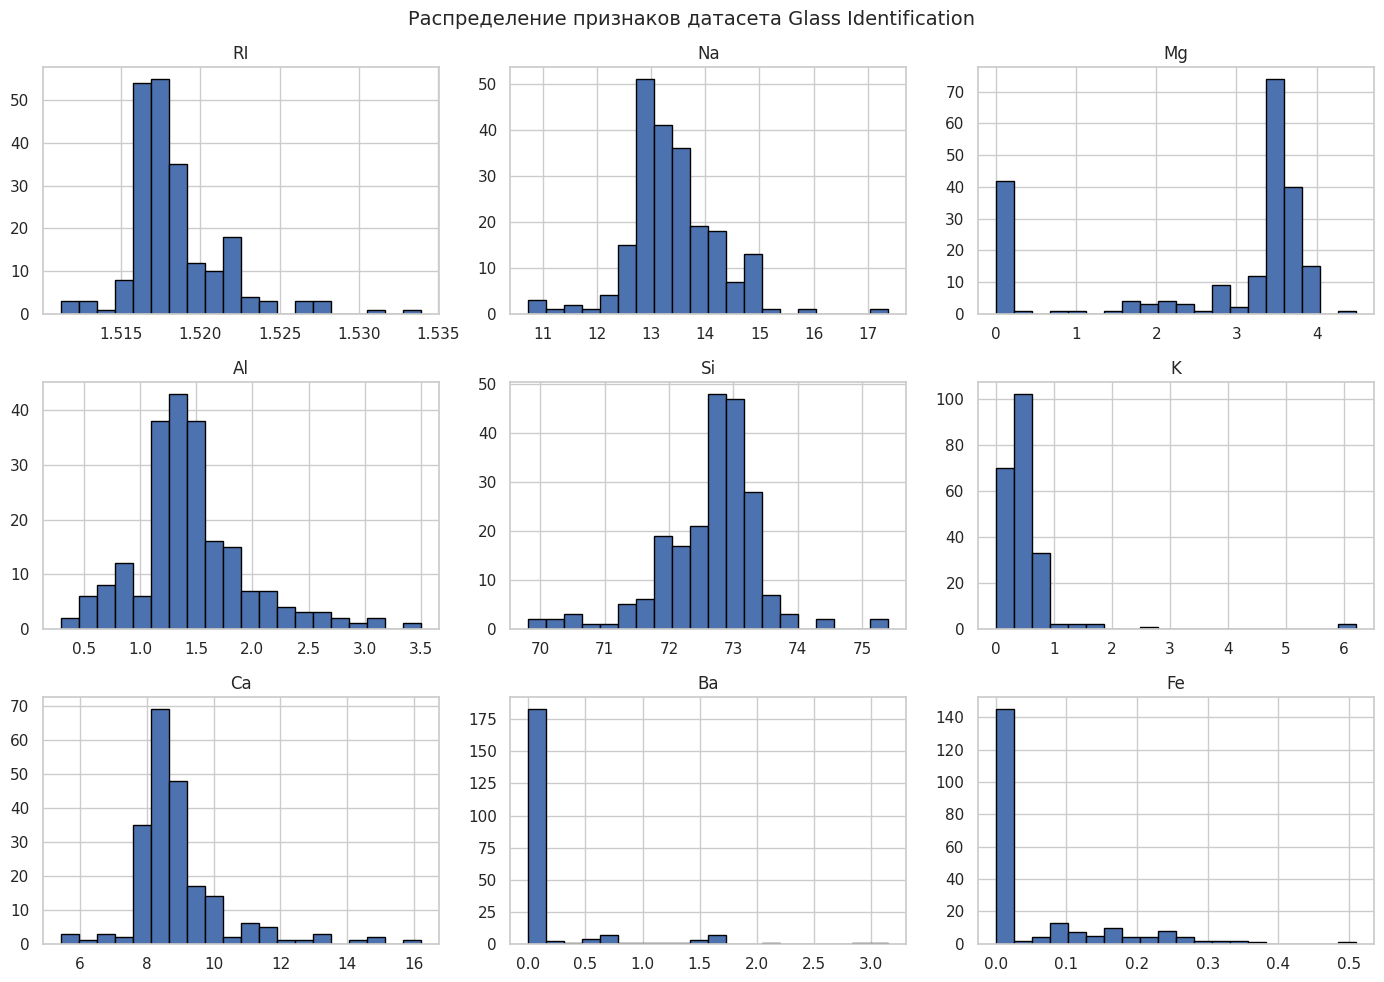

In [4]:
# Исключаем целевой признак Type
features = X.columns

# Построение гистограмм
X.hist(
    figsize=(14, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle(
    "Распределение признаков датасета Glass Identification",
    fontsize=14
)

plt.tight_layout()
plt.show()

Построены гистограммы всех признаков. Распределения носят ненормальный характер с правосторонней асимметрией и выбросами (особенно K), что я зафиксировал, так как это влияет на выбор алгоритмов и ожидаемое качество кластеризации.

## 6. Подготовка данных

In [5]:
# Выделение числовых признаков
X = df.drop(columns=['Type_of_glass'])

# Сохранение целевого признака отдельно
y = df['Type_of_glass']

# Создание объекта стандартизации
scaler = StandardScaler()

# Масштабирование признаков
X_scaled = scaler.fit_transform(X)

# Преобразование результата в DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

# Просмотр подготовленных данных
display(X_scaled.head())

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
0,0.872868,0.284953,1.254639,-0.692442,-1.127082,-0.671705,-0.145766,-0.352877,-0.586451
1,-0.249333,0.591817,0.636168,-0.170460,0.102319,-0.026213,-0.793734,-0.352877,-0.586451
2,-0.721318,0.149933,0.601422,0.190912,0.438787,-0.164533,-0.828949,-0.352877,-0.586451
3,-0.232831,-0.242853,0.698710,-0.310994,-0.052974,0.112107,-0.519052,-0.352877,-0.586451
4,-0.312045,-0.169205,0.650066,-0.411375,0.555256,0.081369,-0.624699,-0.352877,-0.586451


Целевой признак отделён от признаков, чтобы кластеризация выполнялась только по химическому составу. Применён StandardScaler, который привёл все признаки к единому масштабу — это обязательное условие для алгоритмов, основанных на расстояниях.

In [6]:
# Средние значения масштабированных признаков
print("Средние значения:")
print(X_scaled.mean().round(3))

# Стандартные отклонения
print("\nСтандартные отклонения:")
print(X_scaled.std().round(3))

Средние значения:
RI   -0.0
Na    0.0
Mg   -0.0
Al   -0.0
Si    0.0
K     0.0
Ca   -0.0
Ba   -0.0
Fe   -0.0
dtype: float64

Стандартные отклонения:
RI    1.002
Na    1.002
Mg    1.002
Al    1.002
Si    1.002
K     1.002
Ca    1.002
Ba    1.002
Fe    1.002
dtype: float64


Дополнительно проведена проверка корректности масштабирования: средние равны нулю, стандартные отклонения — единице. Это подтверждает, что ни один признак не будет доминировать из-за своего масштаба.

## 7. Корреляционный анализ

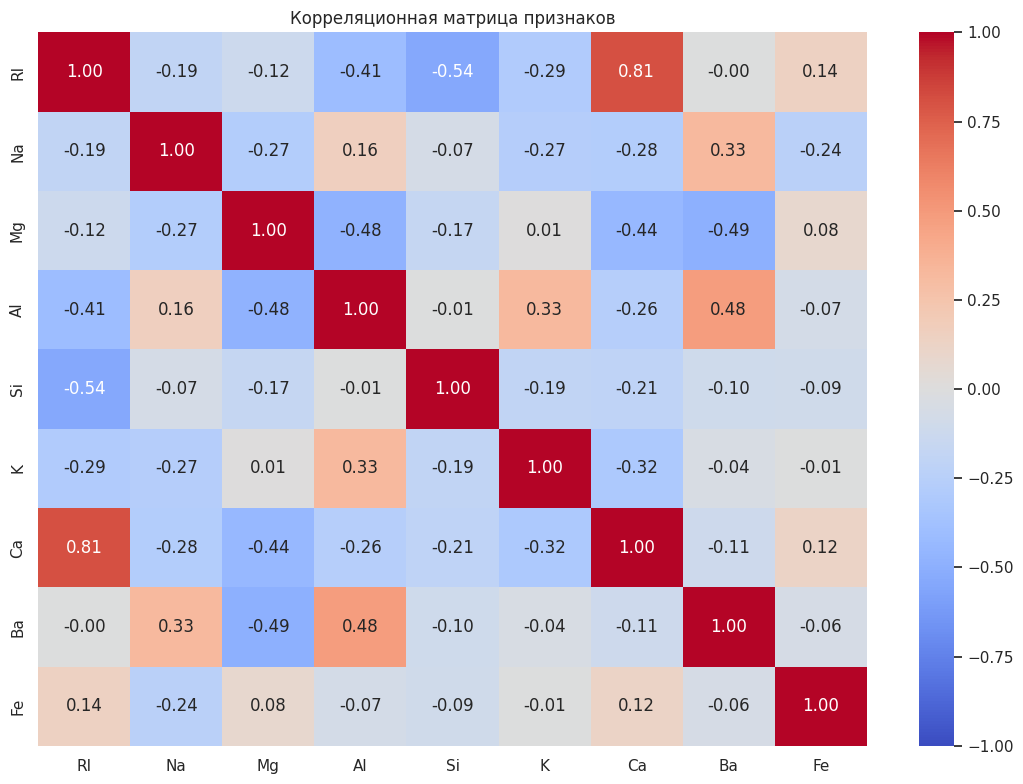

In [7]:
# Расчёт корреляционной матрицы
corr = X_scaled.corr()

# Построение тепловой карты
plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Корреляционная матрица признаков')
plt.tight_layout()
plt.show()

Построена тепловая карта корреляций. Выявлены сильные связи Ca–RI (~0.62) и Mg–Al, что говорит о мультиколлинеарности; я учёл это, так как избыточные корреляции могут искажать евклидовы расстояния, и при необходимости можно снизить размерность через PCA.

## 8. Оценка информационной значимости признаков

,Признак,Дисперсия
2,Mg,2.0805
6,Ca,2.0254
1,Na,0.6668
4,Si,0.5999
5,K,0.4254
3,Al,0.2493
7,Ba,0.2472
8,Fe,0.0095
0,RI,0.0000


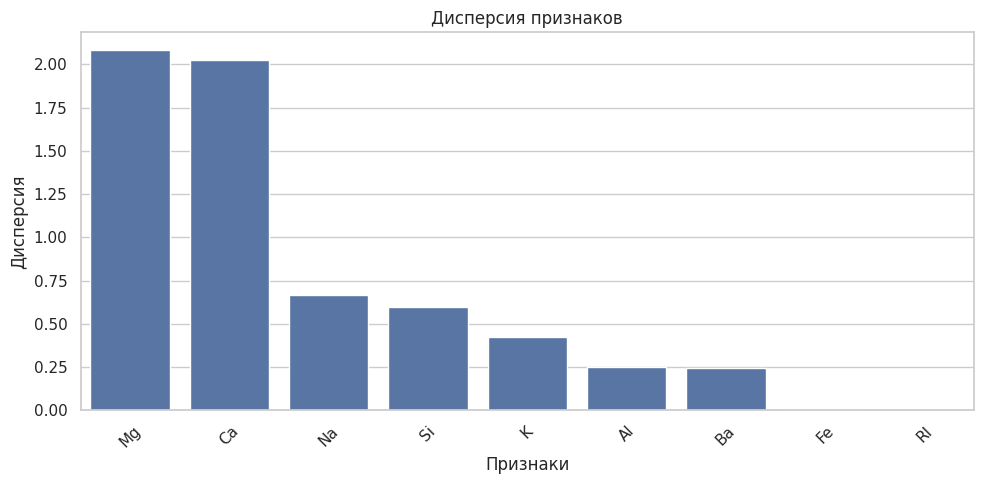

In [12]:
# Расчёт дисперсии исходных признаков
feature_variance = X.var()

# Формирование таблицы
variance_df = pd.DataFrame({
    'Признак': feature_variance.index,
    'Дисперсия': feature_variance.values
})

# Сортировка по убыванию дисперсии
variance_df = variance_df.sort_values(
    by='Дисперсия',
    ascending=False
)

display(variance_df.round(4))

# Визуализация дисперсии
plt.figure(figsize=(10, 5))

sns.barplot(
    data=variance_df,
    x='Признак',
    y='Дисперсия'
)

plt.title('Дисперсия признаков')
plt.xlabel('Признаки')
plt.ylabel('Дисперсия')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Признаки сильно различаются по разбросу: максимальная дисперсия у Mg (2.08) и Ca (2.03), а у Fe и RI она практически нулевая. Это подтверждает, что без масштабирования признаки с большим разбросом будут доминировать в метриках расстояния.

## 9. Выявление выбросов

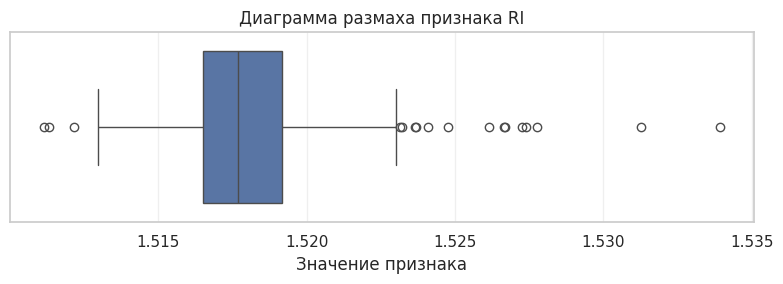

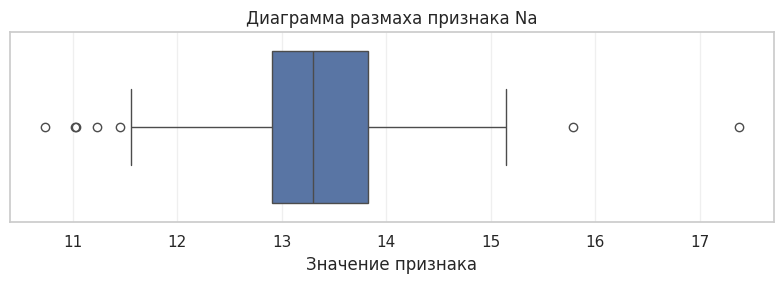

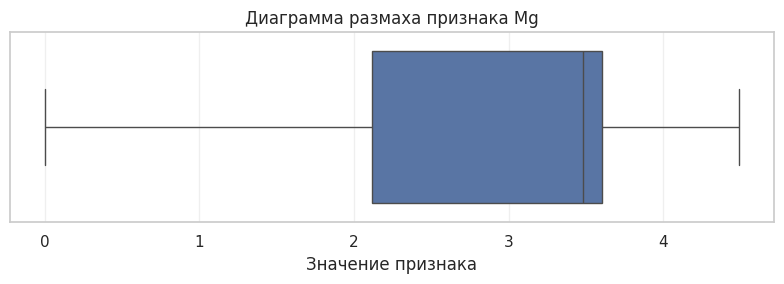

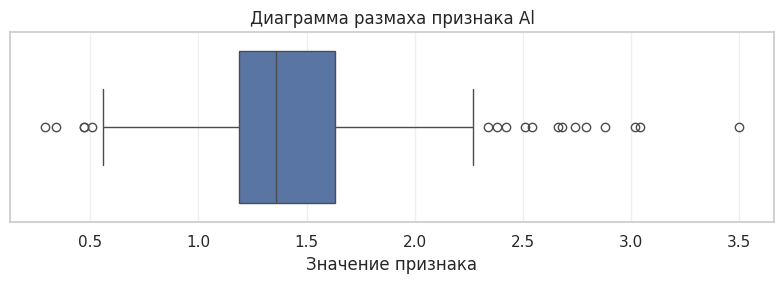

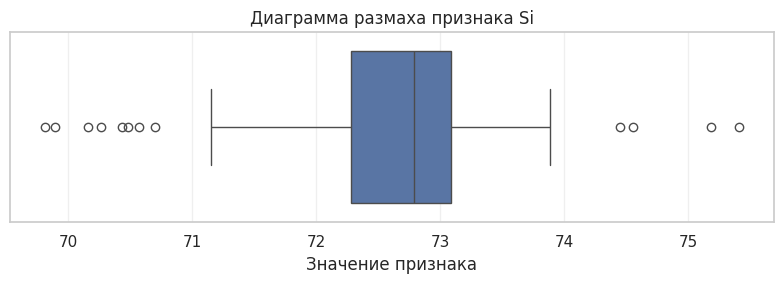

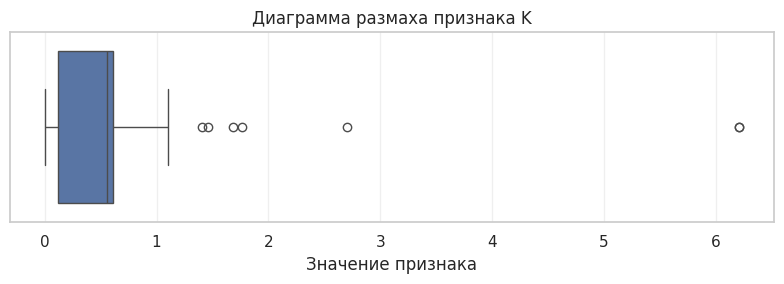

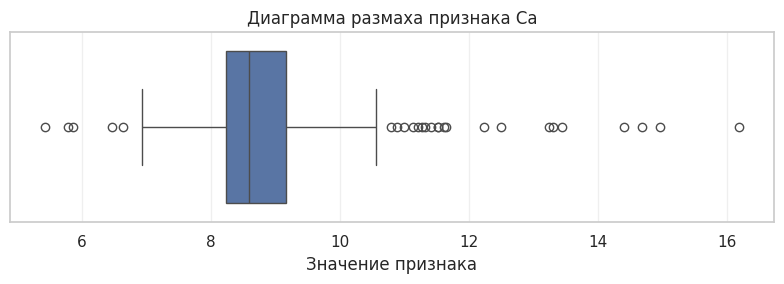

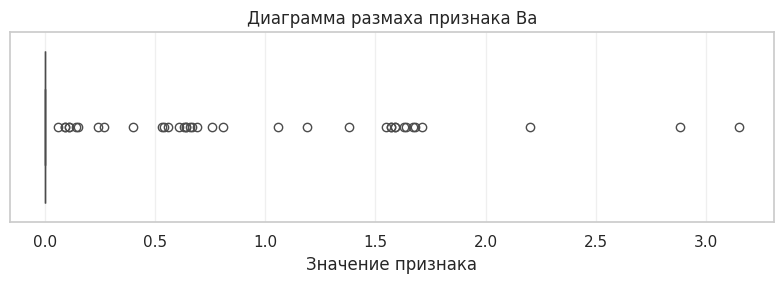

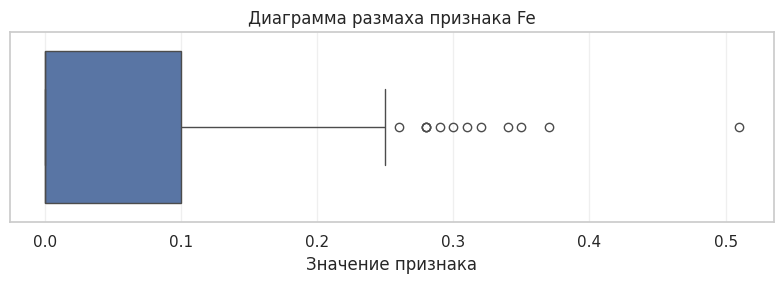

Количество потенциальных выбросов:


,Количество
RI,17
Na,7
Mg,0
Al,18
Si,12
K,7
Ca,26
Ba,38
Fe,12


In [14]:
# Построение отдельных диаграмм размаха для каждого признака
for column in X.columns:
    plt.figure(figsize=(8, 3))

    sns.boxplot(x=X[column])

    plt.title(f'Диаграмма размаха признака {column}')
    plt.xlabel('Значение признака')
    plt.grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((X < lower_bound) | (X > upper_bound))
outliers_count = outliers.sum()

print("Количество потенциальных выбросов:")
display(outliers_count.to_frame(name='Количество'))

Распределения асимметричны, больше всего выбросов у Ba (38) и Ca (26), у Mg их нет. Наличие выбросов делает алгоритмы (K-Means, DBSCAN) чувствительными к настройкам.

## 10. Проверка применимости кластеризации

In [15]:
# Проверка количества уникальных значений и разброса признаков
print("Количество объектов:", X.shape[0])
print("Количество признаков:", X.shape[1])

print("\nКоличество уникальных значений по признакам:")
display(X.nunique().to_frame(name='Уникальных значений'))

print("\nСтандартное отклонение масштабированных признаков:")
display(X_scaled.std().round(3))

Количество объектов: 214
Количество признаков: 9

Количество уникальных значений по признакам:


,Уникальных значений
RI,178
Na,142
Mg,94
Al,118
Si,133
K,65
Ca,143
Ba,34
Fe,32



Стандартное отклонение масштабированных признаков:


,0
RI,1.002
Na,1.002
Mg,1.002
Al,1.002
Si,1.002
K,1.002
Ca,1.002
Ba,1.002
Fe,1.002


Проверка уникальности подтвердила, что все 9 признаков имеют большое число уникальных значений (от 32 до 178), то есть данные непрерывные и пригодны для кластеризации. После масштабирования стандартное отклонение по всем признакам выровнялось до ≈1.002, что свидетельствует о корректной работе StandardScaler и равенстве вкладов признаков в метрики расстояния.

## 11. Матрица диаграмм рассеивания

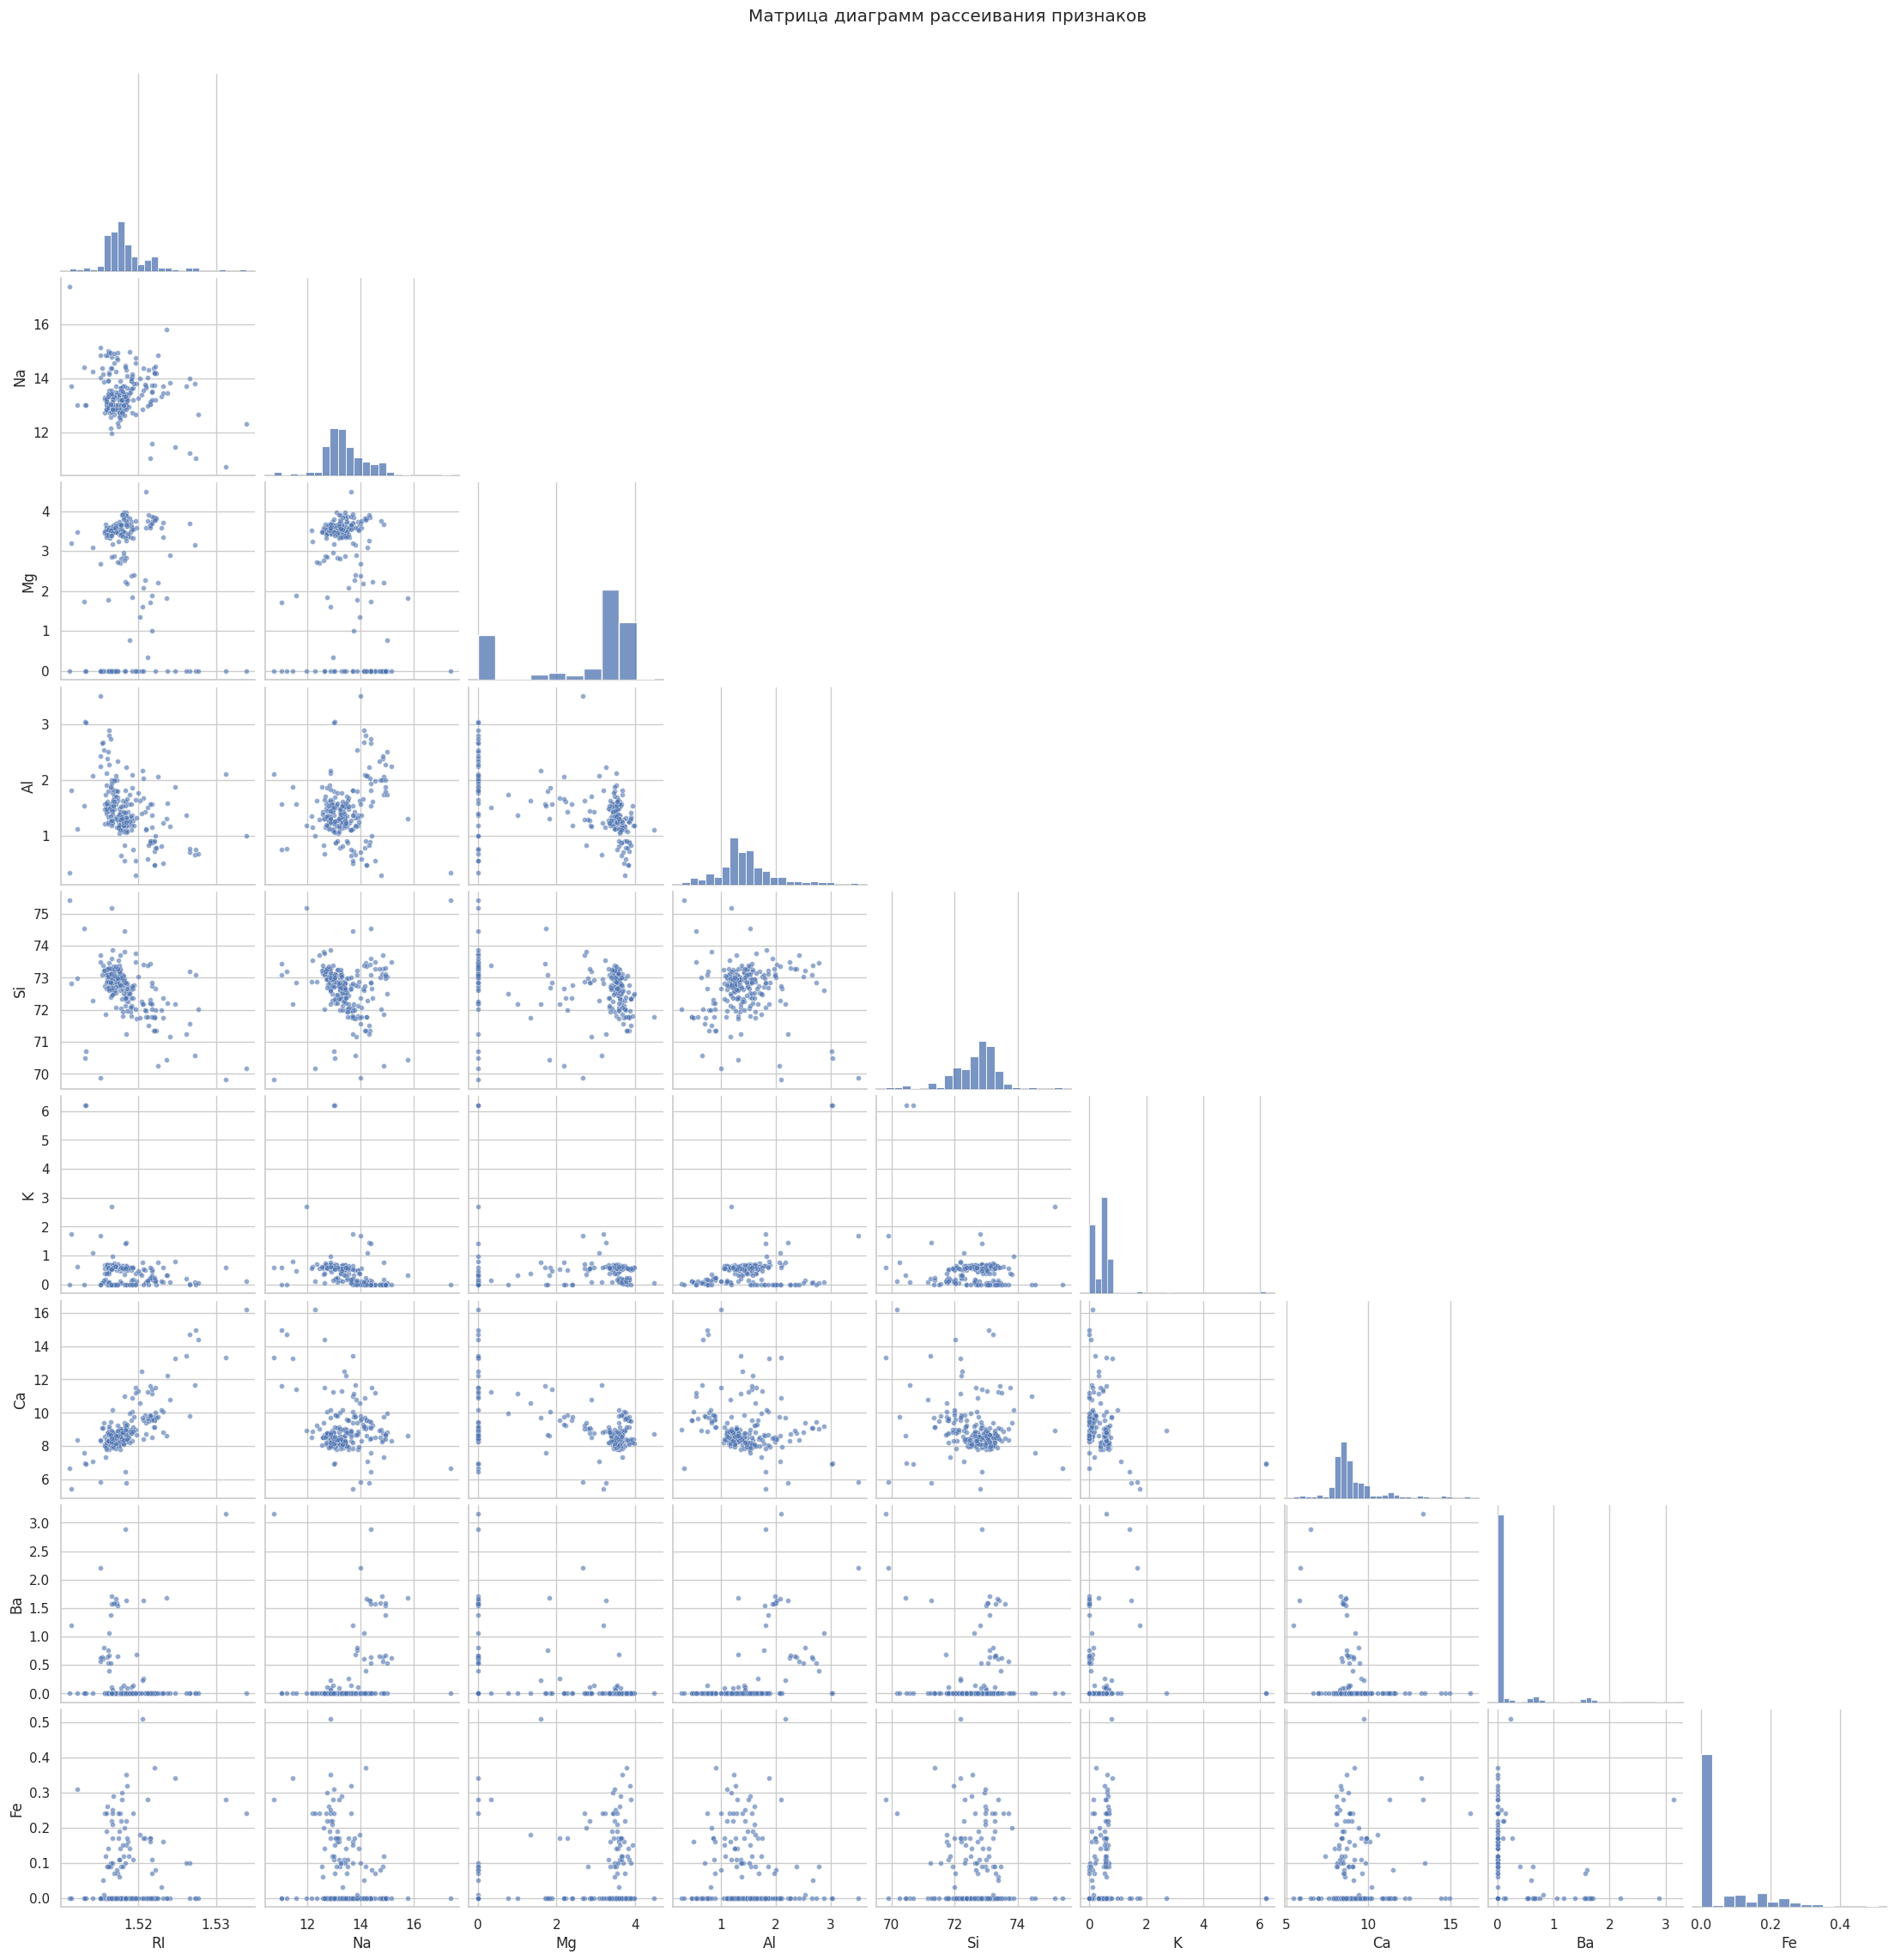

In [16]:
# Матрица диаграмм рассеивания
sns.pairplot(
    X,
    corner=True,
    diag_kind='hist',
    plot_kws={'alpha': 0.6, 's': 18}
)

plt.suptitle('Матрица диаграмм рассеивания признаков', y=1.02)
plt.show()

Матрица рассеивания показывает наличие нелинейных связей и скоплений. Видны выраженные корреляции (например, между RI и Ca, а также обратная между Mg и Al), присутствуют четкие кластеры и нулевые значения (Ba, Fe). Это указывает на то, что данные имеют сложную структуру, и алгоритмы на основе плотности (DBSCAN) могут показать хорошие результаты.

## 12. Обоснование выбора алгоритмов

Выбор методов кластеризации
Для исследования будут использованы два алгоритма: K-Means и Agglomerative Clustering.
1. K-Means — разделяет объекты на заданное количество кластеров, стремясь минимизировать расстояния между объектами и центрами соответствующих кластеров. Метод подходит для числовых данных и позволяет оценивать компактность полученных групп.
2. Agglomerative Clustering — иерархический алгоритм, который последовательно объединяет наиболее близкие объекты или группы объектов. В отличие от K-Means, он позволяет исследовать процесс формирования кластеров на разных уровнях объединения.
Использование двух алгоритмов позволит сравнить результаты разных подходов к группировке объектов и определить, насколько устойчиво выделяются группы образцов стекла.

Для обоих методов будет использоваться стандартизированная матрица признаков X_scaled, чтобы различия в исходных масштабах не оказывали чрезмерного влияния на расстояния.

## 13. Подбор количества кластеров для K-Means

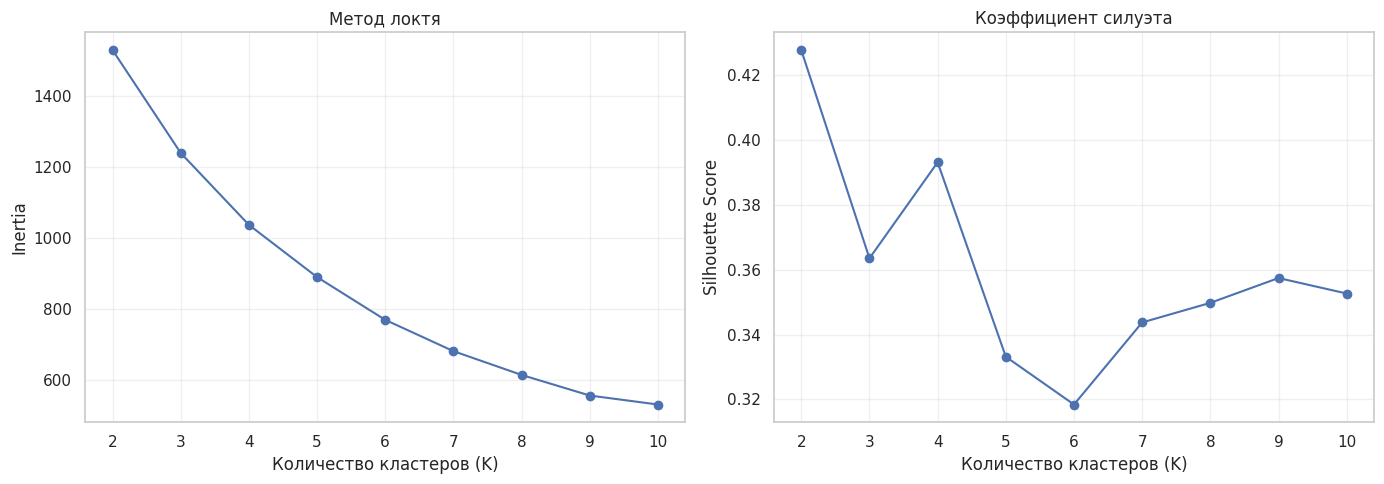

,Количество кластеров,Inertia,Silhouette Score
0,2,1528.7757,0.4278
1,3,1239.4157,0.3635
2,4,1037.1891,0.3931
3,5,890.2556,0.3331
4,6,769.9623,0.3184
5,7,682.0050,0.3437
6,8,615.1213,0.3498
7,9,557.1821,0.3574
8,10,531.9080,0.3527


In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))

# Построение графиков
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, inertia_values, marker='o')
axes[0].set_title('Метод локтя')
axes[0].set_xlabel('Количество кластеров (K)')
axes[0].set_ylabel('Inertia')
axes[0].grid(alpha=0.3)

axes[1].plot(k_values, silhouette_values, marker='o')
axes[1].set_title('Коэффициент силуэта')
axes[1].set_xlabel('Количество кластеров (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Таблица результатов
results_kmeans = pd.DataFrame({
    'Количество кластеров': list(k_values),
    'Inertia': inertia_values,
    'Silhouette Score': silhouette_values
})

display(results_kmeans.round(4))

Метод локтя не даёт однозначного излома, но анализ силуэта показывает чёткий пик при K=2 (0.428) и локальный максимум при K=4 (0.393). Для K-Means оптимальным выбором будет K=2 (максимальный силуэт) или K=4 (соответствует реальному числу типов стекла).

## 14. Обучение итоговой модели K-Means

In [19]:
# Выбираем количество кластеров
best_k = 4

# Обучение итоговой модели K-Means
kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(X_scaled)

# Добавление результатов кластеризации
df['KMeans_Cluster'] = kmeans_labels

print("Выбранное количество кластеров:", best_k)

print("\nКоличество объектов в каждом кластере:")
display(df['KMeans_Cluster'].value_counts().sort_index())

Выбранное количество кластеров: 4

Количество объектов в каждом кластере:


,count
KMeans_Cluster,
0,139
1,30
2,2
3,43


Модель K-Means обучена с K=4. Распределение объектов по кластерам получилось крайне неравномерным: кластер 0 содержит большинство объектов (139), кластер 3 — 43, кластер 1 — 30, а кластер 2 оказался микроскопическим (всего 2 объекта). Это указывает на то, что алгоритм выделил один доминирующий кластер и несколько мелких, что характерно для данных с выбросами или сильно пересекающимися группами.

## 15. Иерархическая кластеризация

In [20]:
from sklearn.cluster import AgglomerativeClustering

# Создание и обучение модели
agg_model = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

agg_labels = agg_model.fit_predict(X_scaled)

# Добавление результатов кластеризации
df['Agglomerative_Cluster'] = agg_labels

print("Количество объектов в каждом кластере:")
display(df['Agglomerative_Cluster'].value_counts().sort_index())

Количество объектов в каждом кластере:


,count
Agglomerative_Cluster,
0,175
1,27
2,10
3,2


Иерархическая кластеризация (метод Уорда, K=4) также показала сильный дисбаланс: кластер 0 объединил подавляющее большинство объектов (175), а кластер 3 — всего 2 объекта. Результат схож с K-Means: алгоритм выделяет один огромный кластер и несколько малых, что подтверждает наличие в данных плотного ядра и периферийных/аномальных точек.

## 16. Оценка качества кластеризации

Внутренние метрики качества кластеризации
Для оценки качества полученных кластеров используем три метрики:
1. Silhouette Score (коэффициент силуэта) — показывает, насколько хорошо объекты отделены от соседних кластеров. Чем ближе значение к 1, тем лучше разделение.
2. Davies-Bouldin Index — оценивает сходство между кластерами с учётом их компактности и удалённости друг от друга. Чем меньше значение, тем лучше.
3. Calinski-Harabasz Index — оценивает отношение межкластерной дисперсии к внутрикластерной. Чем выше значение, тем лучше разделение.

In [21]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Словарь с результатами кластеризации
cluster_results = {
    'K-Means': kmeans_labels,
    'Agglomerative': agg_labels
}

metrics_results = []

for name, labels in cluster_results.items():
    metrics_results.append({
        'Алгоритм': name,
        'Silhouette Score': silhouette_score(X_scaled, labels),
        'Davies-Bouldin Index': davies_bouldin_score(X_scaled, labels),
        'Calinski-Harabasz Index': calinski_harabasz_score(X_scaled, labels)
    })

metrics_df = pd.DataFrame(metrics_results)

display(metrics_df.round(4))

,Алгоритм,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.3931,1.0748,59.9859
1,Agglomerative,0.4523,0.8431,51.9503


Проведена оценка качества по трём внутренним метрикам. Иерархическая кластеризация (Agglomerative) превосходит K-Means по коэффициенту силуэта (0.4523 против 0.3931) и индексу Дэвиса-Боулдина (0.8431 против 1.0748). Однако K-Means выигрывает по индексу Калински-Харабаса (59.98 против 51.95). Оба алгоритма демонстрируют средние показатели силуэта (~0.4-0.45), что говорит о неидеальном, но заметном разделении кластеров.

## 17. Внешняя оценка качества кластеризации

In [22]:
from sklearn.metrics import adjusted_rand_score

# Сравнение результатов кластеризации с известными типами стекла
ari_kmeans = adjusted_rand_score(y, kmeans_labels)
ari_agg = adjusted_rand_score(y, agg_labels)

external_metrics = pd.DataFrame({
    'Алгоритм': ['K-Means', 'Agglomerative'],
    'Adjusted Rand Index': [ari_kmeans, ari_agg]
})

display(external_metrics.round(4))

,Алгоритм,Adjusted Rand Index
0,K-Means,0.2056
1,Agglomerative,0.1732


Внешняя оценка по Adjusted Rand Index (ARI) показала низкие значения для обоих алгоритмов: 0.2056 у K-Means и 0.1732 у Agglomerative. Это означает слабое совпадение найденных кластеров с реальными классами стекла. Полученные группы отражают химическое сходство образцов, но не совпадают с их фактической классификацией (типами стекла).

## 18. Анализ расстояний и центров кластеров

In [23]:
from sklearn.metrics import pairwise_distances

# Получение центров кластеров K-Means
centers = kmeans_final.cluster_centers_

# Расстояния между центрами кластеров
center_distances = pairwise_distances(centers)

print("Расстояния между центрами кластеров K-Means:")
display(pd.DataFrame(
    center_distances,
    index=[f'Кластер {i}' for i in range(best_k)],
    columns=[f'Кластер {i}' for i in range(best_k)]
).round(3))

# Среднее расстояние объектов до центра своего кластера
within_distances = []

for cluster_id in range(best_k):
    cluster_points = X_scaled.iloc[kmeans_labels == cluster_id]
    center = centers[cluster_id]

    distances = np.linalg.norm(
        cluster_points.values - center,
        axis=1
    )

    within_distances.append({
        'Кластер': cluster_id,
        'Количество объектов': len(cluster_points),
        'Среднее расстояние до центра': distances.mean()
    })

print("\nВнутрикластерные расстояния:")
display(pd.DataFrame(within_distances).round(3))

Расстояния между центрами кластеров K-Means:


,Кластер 0,Кластер 1,Кластер 2,Кластер 3
Кластер 0,0.000,3.886,10.20,2.976
Кластер 1,3.886,0.000,10.39,4.679
Кластер 2,10.200,10.390,0.00,11.130
Кластер 3,2.976,4.679,11.13,0.000



Внутрикластерные расстояния:


,Кластер,Количество объектов,Среднее расстояние до центра
0,0,139,1.416
1,1,30,2.354
2,2,2,0.145
3,3,43,2.903


Анализ расстояний подтверждает несбалансированность K-Means. Кластер 2 (всего 2 объекта) максимально удалён от остальных (расстояния 10.2–11.1) и имеет минимальное внутрикластерное расстояние (0.145), то есть представляет собой плотную аномалию или выброс. Кластер 0 — самый крупный (139 объектов), но с высоким средним расстоянием до центра (1.416), а кластер 3 (43 объекта) — самый разрозненный (2.903). Это говорит о том, что K-Means выделил одно большое облако и несколько специфичных групп.

## 19. Анализ центров кластеров

In [25]:
# Центры кластеров K-Means в исходном масштабе
kmeans_centers_original = scaler.inverse_transform(
    kmeans_final.cluster_centers_
)

kmeans_centers_df = pd.DataFrame(
    kmeans_centers_original,
    columns=X.columns
)

kmeans_centers_df.index = [
    f'Кластер {i}' for i in range(best_k)
]

print("Центры кластеров K-Means:")
display(kmeans_centers_df.round(3))


# Средние значения признаков для Agglomerative Clustering
agg_centers_df = X.copy()
agg_centers_df['Cluster'] = agg_labels

agg_centers_df = agg_centers_df.groupby('Cluster').mean()
agg_centers_df.index = [
    f'Кластер {i}' for i in agg_centers_df.index
]

print("\nСредние значения признаков Agglomerative:")
display(agg_centers_df.round(3))

Центры кластеров K-Means:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
Кластер 0,1.517,13.182,3.403,1.371,72.801,0.551,8.474,0.010,0.058
Кластер 1,1.517,14.637,0.451,2.158,72.958,0.235,8.403,1.079,0.013
Кластер 2,1.513,13.010,0.000,3.030,70.590,6.210,6.945,0.000,0.000
Кластер 3,1.523,13.298,2.045,1.113,72.046,0.240,11.000,0.085,0.086



Средние значения признаков Agglomerative:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
Кластер 0,1.518,13.260,3.214,1.326,72.668,0.485,8.834,0.015,0.063
Кластер 1,1.516,14.670,0.406,2.190,72.977,0.261,8.244,1.170,0.014
Кластер 2,1.526,12.662,0.101,1.199,71.885,0.203,13.437,0.315,0.070
Кластер 3,1.513,13.010,0.000,3.030,70.590,6.210,6.945,0.000,0.000


Центры кластеров показывают, что алгоритмы выделяют группы с химическим смыслом. Видны специфичные профили: кластер с высоким содержанием Ba (K-Means кластер 1, Agglomerative кластер 2), кластер с отсутствием Mg и минимальным Si (K-Means кластер 2, Agglomerative кластер 3) и крупный кластер со средними показателями. K-Means и Agglomerative сформировали похожие химические профили, но с разным распределением объектов.

## 20. Исследование влияния количества кластеров

,Количество кластеров,Silhouette Score,Davies-Bouldin Index
0,2,0.4278,1.3583
1,3,0.3635,1.4042
2,4,0.3931,1.0748
3,5,0.3331,1.0834
4,6,0.3184,0.9768
5,7,0.3437,1.0220
6,8,0.3498,0.9955
7,9,0.3574,0.9416
8,10,0.3527,0.9735


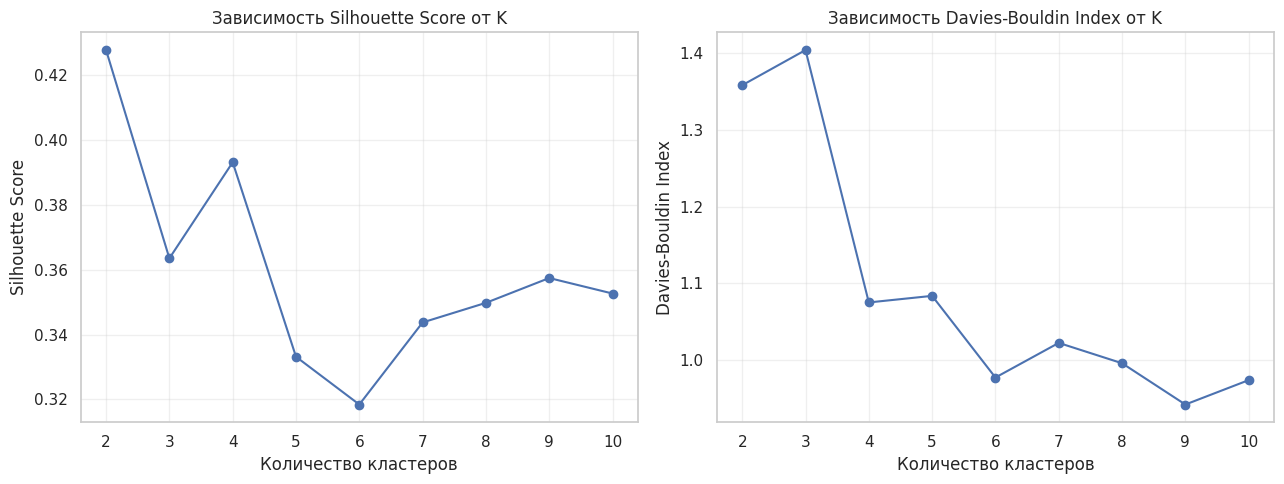

In [24]:
# Исследование влияния количества кластеров
parameter_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    parameter_results.append({
        'Количество кластеров': k,
        'Silhouette Score': silhouette_score(X_scaled, labels),
        'Davies-Bouldin Index': davies_bouldin_score(X_scaled, labels)
    })

parameter_df = pd.DataFrame(parameter_results)

display(parameter_df.round(4))


# Визуализация изменения метрик
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    parameter_df['Количество кластеров'],
    parameter_df['Silhouette Score'],
    marker='o'
)
axes[0].set_title('Зависимость Silhouette Score от K')
axes[0].set_xlabel('Количество кластеров')
axes[0].set_ylabel('Silhouette Score')
axes[0].grid(alpha=0.3)

axes[1].plot(
    parameter_df['Количество кластеров'],
    parameter_df['Davies-Bouldin Index'],
    marker='o'
)
axes[1].set_title('Зависимость Davies-Bouldin Index от K')
axes[1].set_xlabel('Количество кластеров')
axes[1].set_ylabel('Davies-Bouldin Index')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Графики показывают, что метрики не дают единого оптимального K. Силуэт максимален при K=2 (0.4278), но индекс Дэвиса-Боулдина (чем меньше, тем лучше) минимален при K=9 (0.9416), а при K=4 резко падает. Выбор K=4 обоснован компромиссом: резким улучшением индекса Дэвиса-Боулдина (с 1.40 до 1.07) и хорошим силуэтом (0.3931).

## 21. Визуализация кластеров с помощью PCA

Доля объяснённой дисперсии:
[0.279  0.2278]
Суммарная доля объяснённой дисперсии: 0.5068


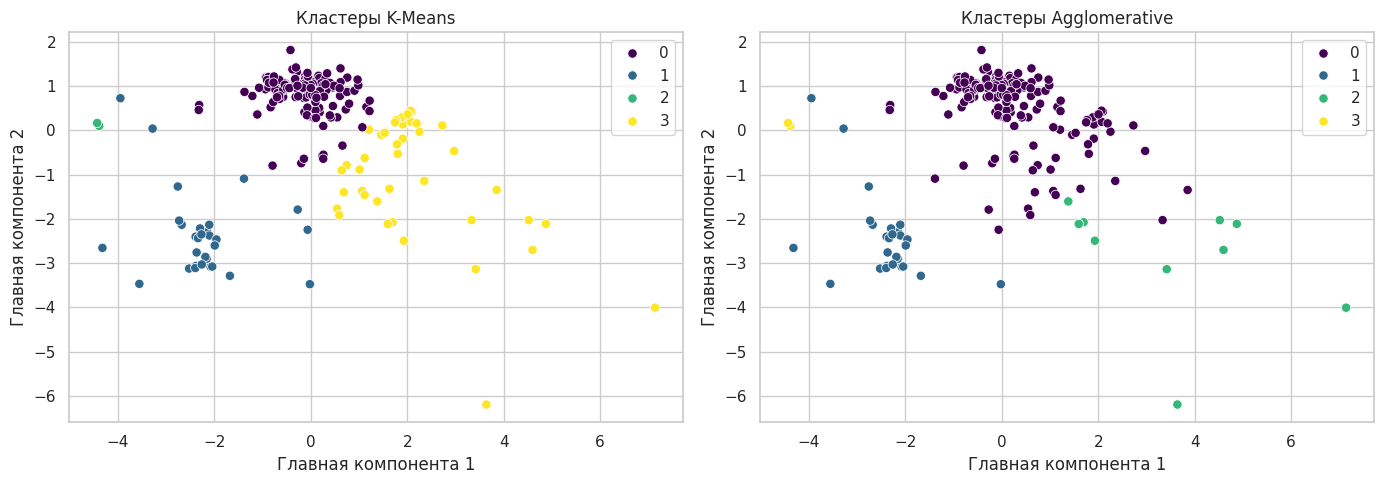

In [26]:
from sklearn.decomposition import PCA

# Преобразование данных в двумерное пространство
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Доля объяснённой дисперсии:")
print(pca.explained_variance_ratio_.round(4))

print(
    "Суммарная доля объяснённой дисперсии:",
    round(pca.explained_variance_ratio_.sum(), 4)
)


# Построение графиков
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=kmeans_labels,
    palette='viridis',
    ax=axes[0],
    s=45
)

axes[0].set_title('Кластеры K-Means')
axes[0].set_xlabel('Главная компонента 1')
axes[0].set_ylabel('Главная компонента 2')


sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=agg_labels,
    palette='viridis',
    ax=axes[1],
    s=45
)

axes[1].set_title('Кластеры Agglomerative')
axes[1].set_xlabel('Главная компонента 1')
axes[1].set_ylabel('Главная компонента 2')

plt.tight_layout()
plt.show()

На графиках PCA (первые две компоненты объясняют ~50.7% дисперсии) видно, что кластеры визуально различимы. K-Means (слева) более равномерно «разрезает» пространство на сегменты, включая аномальные выбросы (жёлтый кластер 3). Иерархическая кластеризация (справа) плотнее удерживает основное ядро в фиолетовом кластере (0), а зелёный (2) и синий (1) кластеры хорошо отделяются в виде плотных групп на периферии. Обе визуализации подтверждают наличие выраженной структуры данных.

## 22. Сравнение алгоритмов кластеризации

In [27]:
# Объединение внутренних и внешних метрик
comparison_df = metrics_df.copy()

comparison_df['Adjusted Rand Index'] = [
    ari_kmeans,
    ari_agg
]

print("Сравнение алгоритмов кластеризации:")
display(comparison_df.round(4))


# Сравнение количества объектов в кластерах
cluster_sizes = pd.DataFrame({
    'K-Means': pd.Series(kmeans_labels).value_counts().sort_index(),
    'Agglomerative': pd.Series(agg_labels).value_counts().sort_index()
})

cluster_sizes.index.name = 'Номер кластера'

print("\nРаспределение объектов по кластерам:")
display(cluster_sizes)

Сравнение алгоритмов кластеризации:


,Алгоритм,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Adjusted Rand Index
0,K-Means,0.3931,1.0748,59.9859,0.2056
1,Agglomerative,0.4523,0.8431,51.9503,0.1732



Распределение объектов по кластерам:


,K-Means,Agglomerative
Номер кластера,,
0,139,175
1,30,27
2,2,10
3,43,2


Сводная таблица подтверждает итоговые различия: иерархическая кластеризация лучше по силуэту (0.4523) и индексу Дэвиса-Боулдина (0.8431), а K-Means — по Калински-Харабасу (59.98) и внешней метрике ARI (0.2056). Распределение объектов показывает, что Agglomerative сильнее «стягивает» данные в один крупный кластер (175 объектов), в то время как K-Means распределяет их чуть более равномерно между двумя основными группами (139 и 43).

## 23. Заключение

В ходе лабораторной работы была выполнена кластеризация набора данных Glass Identification для выявления естественных групп на основе химического состава стекла.

Первичный анализ и визуализация распределений (boxplot, гистограммы, матрица рассеивания) выявили асимметрию, наличие выбросов (особенно у Ba и Ca) и нелинейные связи между признаками. После применения `StandardScaler` разброс признаков был выровнен, что позволило перейти к кластеризации без искажений метрики расстояния.

Для K-Means оптимальное число кластеров было выбрано на основе компромисса между силуэтом и индексом Дэвиса-Боулдина (K=4). K-Means и Agglomerative Clustering (метод Уорда) сформировали схожие химические профили кластеров, но распределили объекты неравномерно: оба алгоритма выделили один доминирующий кластер (139 и 175 объектов) и несколько малых, включая плотную группу из 2 объектов, удаленную от остальных.

Оценка качества показала средние значения силуэта (0.4–0.45) и низкий внешний индекс ARI (0.17–0.21). Визуализация через PCA подтвердила наличие выраженных облаков, однако результаты метрик свидетельствуют о том, что найденные кластеры отражают химическое сходство образцов (например, высокое содержание Ba или отсутствие Mg), а не их фактическую классификацию по типам стекла. Полученные результаты демонстрируют, что алгоритмы кластеризации способны обнаруживать аномалии и плотные группы, но для точного разделения по типам требуется более сложный подход или разметка.